# Two fitted-theory transitions in the momentum scaling law

This notebook marks two transitions of the **fitted theoretical total loss**. The phase-1-to-2 transition is detected from the strongest early change in $d\log \widehat L/d\log k$. The phase-2-to-3 marker denotes entry into the fitted noise-floor regime, defined by the noise floor contributing `NOISE_REGIME_FRACTION` of the late-time fitted total. Experimental transition markers are not shown. The PLK simulation runs on a CUDA or Apple MPS GPU.

In [10]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import torch

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    DTYPE = torch.float64
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    DTYPE = torch.float32
else:
    raise RuntimeError("A CUDA or Apple MPS GPU is required.")

OUTPUT_DIR = Path("results/new_scaling")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"device={DEVICE}, dtype={DTYPE}, torch={torch.__version__}")

device=cuda, dtype=torch.float64, torch=2.12.1+cu130


## Corrected loss prediction

Write $g=1-\rho$ and $\eta_\rho=\eta/g$. In the mixed regime, the unit-prefactor scaling predictions are

$$L_{\rm Polyak}(k)=\underbrace{\rho^k}_{T(k)}+\underbrace{(\eta_\rho k)^{-s}}_{S(k)}+\underbrace{\frac{\sigma^2}{B}\eta_\rho}_{N},$$

$$L_{\rm Nesterov}(k)=\underbrace{\min\{1,(\eta k)^{-s}\}\rho^k}_{T(k)}+\underbrace{(\eta_\rho k)^{-s}}_{S(k)}+\underbrace{\frac{\sigma^2}{B}\min\{\eta_\rho,\eta_\rho^{1/\beta}\}}_{N}.$$

The Nesterov transient is the corrected expression in Theorem 5.2 of `paper.pdf`, not the older $p^k$ expression in Appendix G.2. The first transition is detected directly from the fitted total loss. The second marker is placed only after the fitted noise floor contributes 90 percent of the late-time total, so the local log--log slope has decreased to $-0.1s$ and the curve is visually in the constant-order regime.

In [11]:
B = 64
ETA = 0.06
BETA = 4.0
S = 0.5
SIGMA = 0.2
DIM = 4096
RUNS = 100
TRAIN_STEPS = 20000000
N_CHECKPOINTS = 1_200
SEED = 7
DISPLAY_GAP = 0.03       # rho = 0.97
GAP_MIN = 0.0017          # above the Polyak stability scale eta / B for B=64
GAP_MAX = 0.03            # high-momentum range with the first transition after 2 / eta
N_GAPS = 180
K_MIN = 1.0
K_MAX = float(TRAIN_STEPS)
N_K = 40_000
DERIVATIVE_GRID_POINTS = 2_000
DERIVATIVE_SMOOTH_WINDOW = 31
DERIVATIVE_SEARCH_MIN = 2.0 / ETA
DERIVATIVE_SEARCH_MAX = 10_000.0
NOISE_REGIME_FRACTION = 0.70
ALGORITHMS = ("polyak", "nesterov")
COLORS = {"polyak": "#D94B3D", "nesterov": "#2F5DA8"}

K_GRID = torch.logspace(
    np.log10(K_MIN), np.log10(K_MAX), N_K, device=DEVICE, dtype=DTYPE
)
GAP_GRID = torch.logspace(
    np.log10(GAP_MIN), np.log10(GAP_MAX), N_GAPS, device=DEVICE, dtype=DTYPE
)

## GPU experiment and scaling-law fit

We simulate the finite-dimensional PLK model with fresh curvature-aligned Gaussian gradient noise at every step. The empirical curve is the exact population excess risk averaged over independent GPU replicas. Following Appendix G.2, separate nonnegative coefficients $C_T,C_S,C_N$ are fitted by relative least squares, while the corrected theoretical term shapes remain fixed.

In [12]:
CHECKPOINTS = np.unique(np.concatenate((
    np.asarray([0], dtype=int),
    np.geomspace(1, TRAIN_STEPS, N_CHECKPOINTS).round().astype(int),
))).astype(int)

@torch.no_grad()
def simulate_empirical_curve(algorithm):
    torch.manual_seed(SEED + (0 if algorithm == "polyak" else 10_000))
    j = torch.arange(1, DIM + 1, device=DEVICE, dtype=DTYPE)
    lam = j.pow(-BETA)
    sqrt_lam = lam.sqrt()
    theta_star = j.pow(-0.5 * (1.0 + (S - 1.0) * BETA))
    current = -theta_star.expand(RUNS, -1).clone()
    previous = current.clone()
    rho = 1.0 - DISPLAY_GAP
    checkpoint_set = set(CHECKPOINTS.tolist())
    saved_steps = [0]
    saved_loss = [float((0.5 * (current.square() * lam).sum(dim=1)).mean().item())]
    for step in range(1, TRAIN_STEPS + 1):
        momentum = current - previous
        evaluation = current + rho * momentum if algorithm == "nesterov" else current
        evaluation_loss = 0.5 * (evaluation.square() * lam).sum(dim=1)
        noise_scale = ((evaluation_loss + SIGMA**2) / B).sqrt().unsqueeze(1)
        gradient = evaluation * lam + torch.randn_like(evaluation) * sqrt_lam * noise_scale
        new = current + rho * momentum - ETA * gradient
        previous, current = current, new
        if step in checkpoint_set:
            loss = 0.5 * (current.square() * lam).sum(dim=1)
            saved_steps.append(step)
            saved_loss.append(float(loss.mean().item()))
        if step % 50_000 == 0:
            print(f"  {algorithm}: {step:,}/{TRAIN_STEPS:,} steps", flush=True)
    return np.asarray(saved_steps), np.asarray(saved_loss)

experimental_results = {}
for algorithm in ALGORITHMS:
    print(f"simulating {algorithm} on {DEVICE} ...", flush=True)
    steps, empirical = simulate_empirical_curve(algorithm)
    experimental_results[algorithm] = {"steps": steps, "empirical": empirical}
    print(f"  final empirical loss={empirical[-1]:.6e}", flush=True)

simulating polyak on cuda ...
  polyak: 50,000/20,000,000 steps
  polyak: 100,000/20,000,000 steps
  polyak: 150,000/20,000,000 steps
  polyak: 200,000/20,000,000 steps
  polyak: 250,000/20,000,000 steps
  polyak: 300,000/20,000,000 steps
  polyak: 350,000/20,000,000 steps
  polyak: 400,000/20,000,000 steps
  polyak: 450,000/20,000,000 steps
  polyak: 500,000/20,000,000 steps
  polyak: 550,000/20,000,000 steps
  polyak: 600,000/20,000,000 steps
  polyak: 650,000/20,000,000 steps
  polyak: 700,000/20,000,000 steps
  polyak: 750,000/20,000,000 steps
  polyak: 800,000/20,000,000 steps
  polyak: 850,000/20,000,000 steps
  polyak: 900,000/20,000,000 steps
  polyak: 950,000/20,000,000 steps
  polyak: 1,000,000/20,000,000 steps
  polyak: 1,050,000/20,000,000 steps
  polyak: 1,100,000/20,000,000 steps
  polyak: 1,150,000/20,000,000 steps
  polyak: 1,200,000/20,000,000 steps
  polyak: 1,250,000/20,000,000 steps
  polyak: 1,300,000/20,000,000 steps
  polyak: 1,350,000/20,000,000 steps
  polyak: 

In [13]:
def theory_matrix_at_steps(steps, algorithm, gap=DISPLAY_GAP):
    k = np.maximum(np.asarray(steps, dtype=float), 1.0)
    rho = 1.0 - gap
    eta_rho = ETA / gap
    signal = (eta_rho * k) ** (-S)
    if algorithm == "polyak":
        transient = rho**k
        noise_level = SIGMA**2 / B * eta_rho
    else:
        transient = np.minimum(1.0, (ETA * k) ** (-S)) * rho**k
        noise_level = SIGMA**2 / B * min(eta_rho, eta_rho ** (1.0 / BETA))
    return np.column_stack((transient, signal, np.full_like(k, noise_level)))

def nonnegative_lstsq(x, y):
    best, best_error = np.zeros(x.shape[1]), np.inf
    for mask in range(1, 1 << x.shape[1]):
        active = [index for index in range(x.shape[1]) if mask & (1 << index)]
        active_coef, *_ = np.linalg.lstsq(x[:, active], y, rcond=None)
        if np.any(active_coef < 0):
            continue
        coefficient = np.zeros(x.shape[1])
        coefficient[active] = active_coef
        error = np.mean((x @ coefficient - y) ** 2)
        if error < best_error:
            best, best_error = coefficient, error
    return best

fitted_coefficients = {}
for algorithm in ALGORITHMS:
    result = experimental_results[algorithm]
    terms = theory_matrix_at_steps(result["steps"], algorithm)
    valid = (result["steps"] > 0) & ((ETA / DISPLAY_GAP) * result["steps"] >= 1.0)
    scale = np.maximum(result["empirical"][valid], np.finfo(float).tiny)
    coefficient = nonnegative_lstsq(terms[valid] / scale[:, None], np.ones(valid.sum()))
    result.update(terms=terms, prediction=terms @ coefficient, valid=valid)
    fitted_coefficients[algorithm] = coefficient
    print(algorithm, dict(zip(("C_T", "C_S", "C_N"), coefficient)))

polyak {'C_T': np.float64(0.1257887221358819), 'C_S': np.float64(0.16389440315337872), 'C_N': np.float64(0.2628854744697251)}
nesterov {'C_T': np.float64(0.09212430677900962), 'C_S': np.float64(0.15939160744878447), 'C_N': np.float64(0.17277251310038322)}


In [14]:
def first_derivative_transition(steps, loss):
    """Locate the strongest abrupt change of d log(loss) / d log(step)."""
    steps = np.asarray(steps, dtype=float)
    loss = np.asarray(loss, dtype=float)
    valid = (steps > 0) & np.isfinite(loss) & (loss > 0)
    x = np.log(steps[valid])
    y = np.log(loss[valid])
    x_uniform = np.linspace(x.min(), x.max(), DERIVATIVE_GRID_POINTS)
    y_uniform = np.interp(x_uniform, x, y)
    window = int(DERIVATIVE_SMOOTH_WINDOW)
    if window % 2 == 0:
        window += 1
    pad = window // 2
    kernel = np.ones(window, dtype=float) / window
    y_smooth = np.convolve(np.pad(y_uniform, pad, mode="reflect"), kernel, mode="valid")
    first_derivative = np.gradient(y_smooth, x_uniform)
    derivative_jump = np.abs(np.gradient(first_derivative, x_uniform))
    k_uniform = np.exp(x_uniform)
    search = (k_uniform >= DERIVATIVE_SEARCH_MIN) & (k_uniform <= DERIVATIVE_SEARCH_MAX)
    search[:2 * window] = False
    search[-2 * window:] = False
    score = np.where(search, derivative_jump, -np.inf)
    index = int(np.argmax(score))
    return {
        "k_transition": float(k_uniform[index]), "index": index,
        "k_grid": k_uniform, "smoothed_log_loss": y_smooth,
        "first_derivative": first_derivative, "derivative_jump": derivative_jump,
    }

def fitted_noise_regime_transition(coefficient, algorithm, gap=DISPLAY_GAP):
    """Return k where the noise floor reaches the chosen total-loss fraction."""
    _, signal_coefficient, noise_coefficient = np.asarray(coefficient, dtype=float)
    eta_rho = ETA / gap
    if algorithm == "polyak":
        noise_shape = SIGMA**2 / B * eta_rho
    else:
        noise_shape = SIGMA**2 / B * min(
            eta_rho, eta_rho ** (1.0 / BETA)
        )
    fitted_floor = noise_coefficient * noise_shape
    noise_fraction = float(NOISE_REGIME_FRACTION)
    if not 0.5 < noise_fraction < 1.0:
        raise ValueError("NOISE_REGIME_FRACTION must lie strictly between 0.5 and 1")
    if signal_coefficient <= 0 or fitted_floor <= 0:
        return np.inf
    target_signal = fitted_floor * (1.0 - noise_fraction) / noise_fraction
    return float(
        (signal_coefficient / target_signal) ** (1.0 / S) / eta_rho
    )

theory_transitions = {}
for algorithm in ALGORITHMS:
    result = experimental_results[algorithm]
    first_diagnostic = first_derivative_transition(
        result["steps"], result["prediction"]
    )
    theory_transitions[algorithm] = {
        "phase_1_to_2": first_diagnostic["k_transition"],
        "phase_2_to_3": fitted_noise_regime_transition(
            fitted_coefficients[algorithm], algorithm
        ),
        "first_derivative_diagnostic": first_diagnostic,
    }
    print(algorithm, {
        "phase_1_to_2": theory_transitions[algorithm]["phase_1_to_2"],
        "phase_2_to_3": theory_transitions[algorithm]["phase_2_to_3"],
    })

polyak {'phase_1_to_2': 148.9851543444724, 'phase_2_to_3': 677171.4110311536}
nesterov {'phase_1_to_2': 110.06740136966293, 'phase_2_to_3': 4194016.575106386}


## Figure 1: GPU experiment and fitted scaling-law prediction

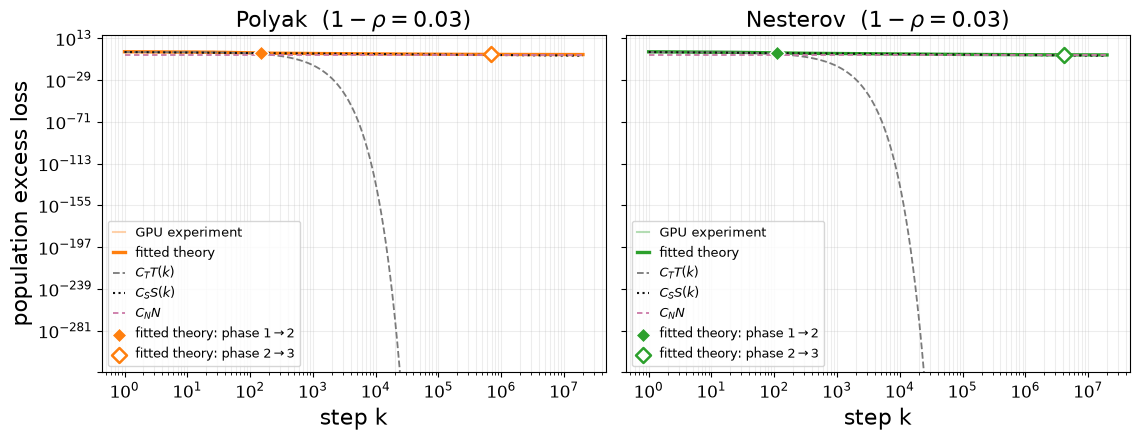

{'polyak': {'phase_1_to_2': 148.9851543444724,
  'phase_2_to_3': 677171.4110311536},
 'nesterov': {'phase_1_to_2': 110.06740136966293,
  'phase_2_to_3': 4194016.575106386}}

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5), sharey=True)

display_transitions = {}

k_np = K_GRID.cpu().numpy()

for axis, algorithm in zip(axes, ALGORITHMS):

    result = experimental_results[algorithm]

    coefficient = fitted_coefficients[algorithm]

    k_phase_1_to_2 = theory_transitions[algorithm]["phase_1_to_2"]

    k_phase_2_to_3 = theory_transitions[algorithm]["phase_2_to_3"]

    display_transitions[algorithm] = {
        "phase_1_to_2": k_phase_1_to_2,
        "phase_2_to_3": k_phase_2_to_3,
    }

    fitted_parts = result["terms"] * coefficient[None, :]

    positive = result["steps"] > 0

    phase_1_to_2_loss = float((
        theory_matrix_at_steps(
            [k_phase_1_to_2],
            algorithm,
        ) @ coefficient
    )[0])

    phase_2_to_3_loss = float((
        theory_matrix_at_steps(
            [k_phase_2_to_3],
            algorithm,
        ) @ coefficient
    )[0])

    axis.loglog(
        result["steps"][positive],
        result["empirical"][positive],
        color=COLORS[algorithm],
        alpha=0.35,
        lw=1.5,
        label="GPU experiment",
    )

    axis.loglog(
        result["steps"][positive],
        result["prediction"][positive],
        color=COLORS[algorithm],
        lw=2.4,
        label="fitted theory",
    )

    axis.loglog(
        result["steps"][positive],
        fitted_parts[positive, 0],
        "--",
        color="#7A7A7A",
        lw=1.3,
        label=r"$C_TT(k)$",
    )

    axis.loglog(
        result["steps"][positive],
        fitted_parts[positive, 1],
        ":",
        color="#111111",
        lw=1.5,
        label=r"$C_SS(k)$",
    )

    axis.loglog(
        result["steps"][positive],
        fitted_parts[positive, 2],
        color="#CC79A7",
        ls=(0, (3, 2)),
        lw=1.3,
        label=r"$C_NN$",
    )

    axis.scatter(
        [k_phase_1_to_2],
        [phase_1_to_2_loss],
        marker="D",
        s=58,
        color=COLORS[algorithm],
        edgecolor="white",
        zorder=5,
        label=r"fitted theory: phase $1\to2$",
    )

    axis.scatter(
        [k_phase_2_to_3],
        [phase_2_to_3_loss],
        marker="D",
        s=58,
        facecolor="white",
        edgecolor=COLORS[algorithm],
        linewidth=1.8,
        zorder=5,
        label=r"fitted theory: phase $2\to3$",
    )

    axis.set(
        title=algorithm.capitalize()
        + rf"  ($1-\rho={DISPLAY_GAP}$)",
        xlabel="step k",
    )

    axis.grid(
        True,
        which="both",
        alpha=0.22,
    )

    axis.legend(fontsize=9)

axes[0].set_ylabel("population excess loss")

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "scaling_prediction_with_derivative_transition.png",
    dpi=220,
    bbox_inches="tight",
)

fig.savefig(
    OUTPUT_DIR
    / "scaling_prediction_with_derivative_transition.pdf",
    bbox_inches="tight",
)

plt.show()

display_transitions

## Standalone total-loss prediction

This figure overlays the GPU empirical total loss and the fitted theoretical total $\widehat L(k)=C_TT(k)+C_SS(k)+C_NN$, without showing the component curves. Only fitted-theory transitions are marked: a filled diamond denotes phase $1\to2$, and an open diamond denotes phase $2\to3$. No empirical transition marker is shown.

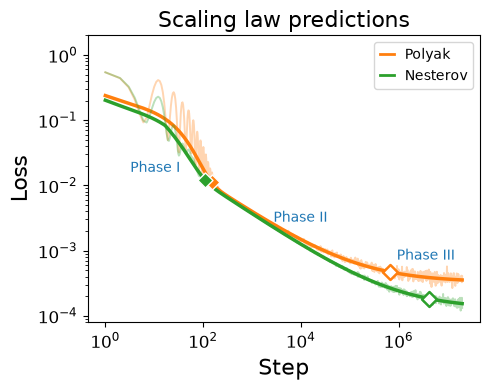

In [38]:
from matplotlib.lines import Line2D


# =============================================================================
# Plot config: aligned with blow_up(2).py
# =============================================================================

NOISE_REGIME_FRACTION = 0.50

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "sans-serif",
    "axes.titlesize": 16,
    "axes.labelsize": 16,
    "lines.linewidth": 2,
    "lines.markersize": 6,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.figsize": (5, 4),
    "legend.fontsize": 10,
    "legend.handlelength": 1,
})

COLORS = {
    "polyak": "C1",
    "nesterov": "C2",
}

PHASE_LABEL_COLOR = "C0"


# =============================================================================
# Plot
# =============================================================================

fig, ax = plt.subplots()

for algorithm in ALGORITHMS:

    result = experimental_results[algorithm]

    positive = result["steps"] > 0

    coefficient = fitted_coefficients[algorithm]

    k_phase_1_to_2 = float(
        display_transitions[algorithm]["phase_1_to_2"]
    )

    k_phase_2_to_3 = float(
        display_transitions[algorithm]["phase_2_to_3"]
    )

    phase_1_to_2_loss = float((
        theory_matrix_at_steps(
            [k_phase_1_to_2],
            algorithm,
        ) @ coefficient
    )[0])

    phase_2_to_3_loss = float((
        theory_matrix_at_steps(
            [k_phase_2_to_3],
            algorithm,
        ) @ coefficient
    )[0])

    # GPU experiment
    ax.loglog(
        result["steps"][positive],
        result["empirical"][positive],
        color=COLORS[algorithm],
        alpha=0.32,
        lw=1.4,
    )

    # Fitted scaling-law prediction
    ax.loglog(
        result["steps"][positive],
        result["prediction"][positive],
        color=COLORS[algorithm],
        lw=2.5,
    )

    # Phase I -> Phase II transition
    ax.scatter(
        [k_phase_1_to_2],
        [phase_1_to_2_loss],
        color=COLORS[algorithm],
        marker="D",
        s=58,
        edgecolor="white",
        zorder=5,
    )

    # Phase II -> Phase III transition
    ax.scatter(
        [k_phase_2_to_3],
        [phase_2_to_3_loss],
        facecolor="white",
        edgecolor=COLORS[algorithm],
        marker="D",
        s=58,
        linewidth=1.8,
        zorder=5,
    )


# =============================================================================
# Phase labels: each phase is shown only once
# =============================================================================

def fitted_loss_at(step, algorithm):

    coefficient = fitted_coefficients[algorithm]

    return float((
        theory_matrix_at_steps(
            [step],
            algorithm,
        ) @ coefficient
    )[0])


# Phase I: below the green Nesterov curve
green_algorithm = "nesterov"

green_steps = np.asarray(
    experimental_results[green_algorithm]["steps"],
    dtype=float,
)

green_steps = green_steps[green_steps > 0]

green_k12 = float(
    display_transitions[green_algorithm]["phase_1_to_2"]
)

phase_1_x = np.sqrt(
    green_steps.min() * green_k12
)

phase_1_y = fitted_loss_at(
    phase_1_x,
    green_algorithm,
)

ax.annotate(
    r"Phase $\mathrm{I}$",
    xy=(phase_1_x, phase_1_y),
    xytext=(0, -30),
    textcoords="offset points",
    color=PHASE_LABEL_COLOR,
    fontsize=10,
    ha="center",
    va="top",
    zorder=6,
)


# Phase II and Phase III: around the orange Polyak curve
orange_algorithm = "polyak"

orange_steps = np.asarray(
    experimental_results[orange_algorithm]["steps"],
    dtype=float,
)

orange_steps = orange_steps[orange_steps > 0]

orange_k12 = float(
    display_transitions[orange_algorithm]["phase_1_to_2"]
)

orange_k23 = float(
    display_transitions[orange_algorithm]["phase_2_to_3"]
)


# Phase II: above the orange curve
phase_2_x = np.sqrt(
    orange_k12 * orange_k23
)

phase_2_y = fitted_loss_at(
    phase_2_x,
    orange_algorithm,
)

ax.annotate(
    r"Phase $\mathrm{II}$",
    xy=(phase_2_x, phase_2_y),
    xytext=(0, 10),
    textcoords="offset points",
    color=PHASE_LABEL_COLOR,
    fontsize=10,
    ha="center",
    va="bottom",
    zorder=6,
)


# Phase III: close to the orange curve
phase_3_x = np.sqrt(
    orange_k23 * orange_steps.max()
)

phase_3_y = fitted_loss_at(
    phase_3_x,
    orange_algorithm,
)

ax.annotate(
    r"Phase $\mathrm{III}$",
    xy=(phase_3_x, phase_3_y),
    xytext=(0, 10),
    textcoords="offset points",
    color=PHASE_LABEL_COLOR,
    fontsize=10,
    ha="center",
    va="bottom",
    zorder=6,
)


# =============================================================================
# Axes and legend
# =============================================================================

legend_handles = [
    Line2D(
        [0],
        [0],
        color=COLORS[algorithm],
        lw=2,
        label=algorithm.capitalize(),
    )
    for algorithm in ALGORITHMS
]

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(top=2)

ax.set_xlabel("Step")
ax.set_ylabel("Loss")
ax.set_title("Scaling law predictions")

ax.legend(
    handles=legend_handles,
    loc="best",
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "total_loss_experiment_vs_theory.pdf",
    bbox_inches="tight",
)

fig.savefig(
    OUTPUT_DIR / "total_loss_experiment_vs_theory.png",
    bbox_inches="tight",
    dpi=200,
)

plt.show()

## Figure 2: derivative-detected transition versus $1-\rho$

For each momentum gap, the fitted theoretical total loss is constructed first. The phase-$1\to2$ transition is detected solely from the strongest early change in $d\log \widehat L/d\log k$. The search starts at $k=2/\eta$ so that Nesterov's algebraic kink from the literal $\min\{1,(\eta k)^{-s}\}$ expression at $k=1/\eta$ is not misidentified as the dynamical transition. No empirical transition marker is shown.

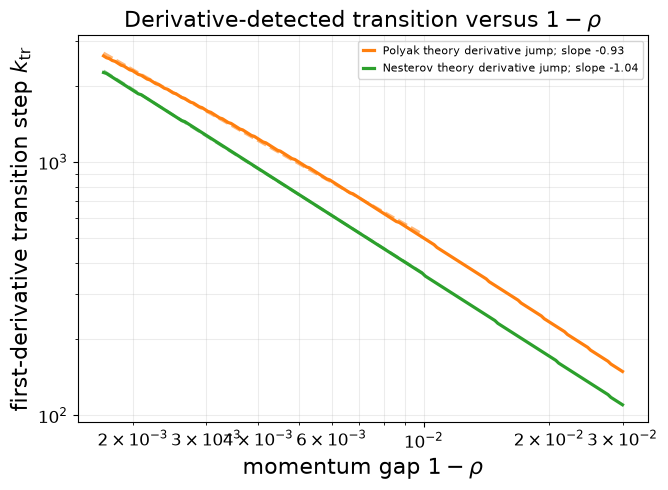

{'polyak': {'small_gap_loglog_slope': -0.9322013826657475,
  'intercept': 1.9536012797314892},
 'nesterov': {'small_gap_loglog_slope': -1.0402910388332087,
  'intercept': 1.100674843149722}}

In [39]:
gap_np = GAP_GRID.cpu().numpy()

k_np = K_GRID.cpu().numpy()

transition_by_algorithm = {}

for algorithm in ALGORITHMS:

    coefficient = fitted_coefficients[algorithm]

    transition_by_algorithm[algorithm] = np.asarray([
        first_derivative_transition(
            k_np,
            theory_matrix_at_steps(
                k_np,
                algorithm,
                float(gap),
            ) @ coefficient,
        )["k_transition"]
        for gap in gap_np
    ])


fig, ax = plt.subplots(figsize=(6.8, 5.0))

fit_summary = {}

transition_fit_by_algorithm = {}

for algorithm in ALGORITHMS:

    transition_np = transition_by_algorithm[algorithm]

    valid = np.isfinite(transition_np)

    small_gap = valid & (gap_np <= 0.01)

    slope, intercept = np.polyfit(
        np.log(gap_np[small_gap]),
        np.log(transition_np[small_gap]),
        1,
    )

    fit_summary[algorithm] = {
        "small_gap_loglog_slope": float(slope),
        "intercept": float(intercept),
    }

    ax.loglog(
        gap_np[valid],
        transition_np[valid],
        color=COLORS[algorithm],
        lw=2.3,
        label=(
            f"{algorithm.capitalize()} theory derivative jump; "
            f"slope {slope:.2f}"
        ),
    )

    # Save exactly the dashed fitted values shown in the figure.
    fitted_transition = np.full_like(
        gap_np,
        np.nan,
        dtype=float,
    )

    fitted_transition[small_gap] = (
        np.exp(intercept)
        * gap_np[small_gap] ** slope
    )

    transition_fit_by_algorithm[algorithm] = (
        fitted_transition
    )

    ax.loglog(
        gap_np[small_gap],
        fitted_transition[small_gap],
        "--",
        color=COLORS[algorithm],
        alpha=0.55,
    )


ax.set(
    xlabel=r"momentum gap $1-\rho$",
    ylabel=r"first-derivative transition step $k_{\rm tr}$",
    title=r"Derivative-detected transition versus $1-\rho$",
)

ax.grid(
    True,
    which="both",
    alpha=0.24,
)

ax.legend(fontsize=8)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "derivative_transition_vs_one_minus_rho.png",
    dpi=220,
    bbox_inches="tight",
)

fig.savefig(
    OUTPUT_DIR
    / "derivative_transition_vs_one_minus_rho.pdf",
    bbox_inches="tight",
)

plt.show()

fit_summary

In [40]:
# =============================================================================
# Remove numerical files generated by the old saving block
# =============================================================================

old_data_files = (
    OUTPUT_DIR / "derivative_transition_summary.json",
    OUTPUT_DIR / "derivative_transition_vs_gap.npz",
    OUTPUT_DIR / "empirical_polyak.npz",
    OUTPUT_DIR / "empirical_nesterov.npz",
)

for data_path in old_data_files:

    if data_path.exists():
        data_path.unlink()


# =============================================================================
# 1. Scaling-law prediction curves
# =============================================================================

polyak_result = experimental_results["polyak"]

polyak_positive = polyak_result["steps"] > 0

nesterov_result = experimental_results["nesterov"]

nesterov_positive = nesterov_result["steps"] > 0


np.savez_compressed(
    OUTPUT_DIR / "scaling_law_prediction_data.npz",

    polyak_steps=np.asarray(
        polyak_result["steps"][polyak_positive],
        dtype=float,
    ),

    polyak_original_loss=np.asarray(
        polyak_result["empirical"][polyak_positive],
        dtype=float,
    ),

    polyak_fitted_loss=np.asarray(
        polyak_result["prediction"][polyak_positive],
        dtype=float,
    ),

    nesterov_steps=np.asarray(
        nesterov_result["steps"][nesterov_positive],
        dtype=float,
    ),

    nesterov_original_loss=np.asarray(
        nesterov_result["empirical"][nesterov_positive],
        dtype=float,
    ),

    nesterov_fitted_loss=np.asarray(
        nesterov_result["prediction"][nesterov_positive],
        dtype=float,
    ),
)


# =============================================================================
# 2. Transition curves for different rho values
# =============================================================================

np.savez_compressed(
    OUTPUT_DIR
    / "transition_vs_one_minus_rho_data.npz",

    rho=np.asarray(
        1.0 - gap_np,
        dtype=float,
    ),

    one_minus_rho=np.asarray(
        gap_np,
        dtype=float,
    ),

    polyak_transition=np.asarray(
        transition_by_algorithm["polyak"],
        dtype=float,
    ),

    polyak_fitted_transition=np.asarray(
        transition_fit_by_algorithm["polyak"],
        dtype=float,
    ),

    nesterov_transition=np.asarray(
        transition_by_algorithm["nesterov"],
        dtype=float,
    ),

    nesterov_fitted_transition=np.asarray(
        transition_fit_by_algorithm["nesterov"],
        dtype=float,
    ),
)


print(
    "Saved numerical plotting data to:"
)

print(
    OUTPUT_DIR
    / "scaling_law_prediction_data.npz"
)

print(
    OUTPUT_DIR
    / "transition_vs_one_minus_rho_data.npz"
)

Saved numerical plotting data to:
results/new_scaling/scaling_law_prediction_data.npz
results/new_scaling/transition_vs_one_minus_rho_data.npz


Reading data from: /Users/wangjianan/Downloads/exp/results/new_scaling
Saving figures to: /Users/wangjianan/Downloads/exp/new
Displayed transition boundary: 148.9851543444724
Saved PNG to: /Users/wangjianan/Downloads/exp/new/total_loss_experiment_vs_theory.png
Saved PDF to: /Users/wangjianan/Downloads/exp/new/total_loss_experiment_vs_theory.pdf


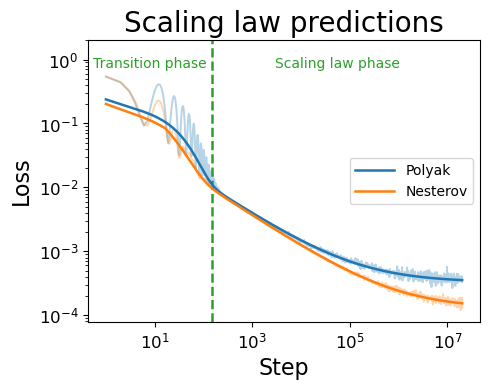

In [1]:
# =============================================================================
# Reload saved data and save the new figure to Desktop/new
# =============================================================================

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D


PROJECT_DIR = Path.cwd()

DATA_DIR = (
    PROJECT_DIR
    / "results"
    / "new_scaling"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "new"
)


OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SCALING_DATA_PATH = (
    DATA_DIR
    / "scaling_law_prediction_data.npz"
)

TRANSITION_DATA_PATH = (
    DATA_DIR
    / "transition_vs_one_minus_rho_data.npz"
)

PNG_PATH = (
    OUTPUT_DIR
    / "total_loss_experiment_vs_theory.png"
)

PDF_PATH = (
    OUTPUT_DIR
    / "total_loss_experiment_vs_theory.pdf"
)

print(
    "Reading data from:",
    DATA_DIR.resolve(),
)

print(
    "Saving figures to:",
    OUTPUT_DIR.resolve(),
)


# =============================================================================
# Algorithms and colors
# =============================================================================

ALGORITHMS = (
    "polyak",
    "nesterov",
)

COLORS = {
    "polyak": "tab:blue",
    "nesterov": "tab:orange",
}

PHASE_COLOR = "tab:green"

DISPLAY_GAP = 0.03


# =============================================================================
# Plot configuration: aligned with new_stability.ipynb
# =============================================================================

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.labelsize": 16,
    "axes.titlesize": 20,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
})


# =============================================================================
# Check that the saved data exist
# =============================================================================

if not SCALING_DATA_PATH.exists():

    raise FileNotFoundError(
        "Scaling-law data were not found at:\n"
        f"{SCALING_DATA_PATH.resolve()}"
    )

if not TRANSITION_DATA_PATH.exists():

    raise FileNotFoundError(
        "Transition data were not found at:\n"
        f"{TRANSITION_DATA_PATH.resolve()}"
    )


# =============================================================================
# Load scaling-law data
# =============================================================================

with np.load(
    SCALING_DATA_PATH,
    allow_pickle=False,
) as data:

    scaling_data = {
        key: np.asarray(
            data[key],
            dtype=float,
        )
        for key in data.files
    }


# =============================================================================
# Load transition data
# =============================================================================

with np.load(
    TRANSITION_DATA_PATH,
    allow_pickle=False,
) as data:

    transition_data = {
        key: np.asarray(
            data[key],
            dtype=float,
        )
        for key in data.files
    }


# =============================================================================
# Find the boundary between the two phases
# =============================================================================

gap_index = int(
    np.argmin(
        np.abs(
            transition_data[
                "one_minus_rho"
            ]
            - DISPLAY_GAP
        )
    )
)

first_transition_steps = np.asarray([
    transition_data[
        "polyak_transition"
    ][gap_index],
    transition_data[
        "nesterov_transition"
    ][gap_index],
])

first_transition_steps = first_transition_steps[
    np.isfinite(first_transition_steps)
    & (first_transition_steps > 0)
]

if first_transition_steps.size == 0:

    raise ValueError(
        "No valid transition step was found."
    )

boundary_step = float(
    np.max(first_transition_steps)
)

print(
    "Displayed transition boundary:",
    boundary_step,
)


# =============================================================================
# Plot
# =============================================================================

fig, ax = plt.subplots(
    figsize=(5.0, 4.0)
)

all_steps = []

for algorithm in ALGORITHMS:

    steps = scaling_data[
        f"{algorithm}_steps"
    ]

    original_loss = scaling_data[
        f"{algorithm}_original_loss"
    ]

    fitted_loss = scaling_data[
        f"{algorithm}_fitted_loss"
    ]

    valid = (
        (steps > 0)
        & np.isfinite(steps)
        & np.isfinite(original_loss)
        & np.isfinite(fitted_loss)
        & (original_loss > 0)
        & (fitted_loss > 0)
    )

    steps = steps[valid]
    original_loss = original_loss[valid]
    fitted_loss = fitted_loss[valid]

    all_steps.append(steps)

    # Empirical loss
    ax.loglog(
        steps,
        original_loss,
        color=COLORS[algorithm],
        alpha=0.32,
        lw=1.4,
        zorder=2,
    )

    # Fitted scaling-law prediction
    ax.loglog(
        steps,
        fitted_loss,
        color=COLORS[algorithm],
        lw=1.8,
        zorder=3,
    )


# =============================================================================
# Transition/scaling-law boundary
# =============================================================================

all_steps = np.concatenate(
    all_steps
)

minimum_step = float(
    np.min(all_steps)
)

maximum_step = float(
    np.max(all_steps)
)

ax.axvline(
    boundary_step,
    color=PHASE_COLOR,
    linestyle="--",
    linewidth=1.8,
    zorder=1,
)


# =============================================================================
# Phase-label positions
# =============================================================================

transition_label_x = (
    0.65
    * np.sqrt(
        minimum_step
        * boundary_step
    )
)

scaling_label_x = np.sqrt(
    boundary_step
    * maximum_step
)

label_transform = (
    ax.get_xaxis_transform()
)


# =============================================================================
# Phase labels
# =============================================================================

ax.text(
    transition_label_x,
    0.94,
    "Transition phase",
    transform=label_transform,
    color=PHASE_COLOR,
    fontsize=10,
    ha="center",
    va="top",
)

ax.text(
    scaling_label_x,
    0.94,
    "Scaling law phase",
    transform=label_transform,
    color=PHASE_COLOR,
    fontsize=10,
    ha="center",
    va="top",
)


# =============================================================================
# Legend
# =============================================================================

legend_handles = [
    Line2D(
        [0],
        [0],
        color=COLORS[algorithm],
        lw=1.8,
        label=algorithm.capitalize(),
    )
    for algorithm in ALGORITHMS
]


# =============================================================================
# Axes
# =============================================================================

ax.set_xscale(
    "log"
)

ax.set_yscale(
    "log"
)

ax.set_ylim(
    top=2,
)

ax.set_xlabel(
    "Step",
    fontsize=16,
)

ax.set_ylabel(
    "Loss",
    fontsize=16,
)

ax.set_title(
    "Scaling law predictions",
    fontsize=20,
)

ax.tick_params(
    axis="both",
    labelsize=12,
)

ax.grid(
    False
)

ax.legend(
    handles=legend_handles,
    loc="center right",
    fontsize=10,
    handlelength=2.8,
)


# =============================================================================
# Layout and save
# =============================================================================

fig.tight_layout()

fig.savefig(
    PNG_PATH,
    dpi=180,
    bbox_inches="tight",
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight",
)

print(
    "Saved PNG to:",
    PNG_PATH.resolve(),
)

print(
    "Saved PDF to:",
    PDF_PATH.resolve(),
)

plt.show()